In [1]:
import torch
import time

# config matching tiedw_residual_gelu
B, T, C = 4, 512, 768
mlp_mult = 4.0
mlp_hidden = int(mlp_mult * C)  # 3072
runs = 1000
device = "cuda"

print(f"Config: B={B}, T={T}, C={C}, mlp_hidden={mlp_hidden}")
print(f"Device: {torch.cuda.get_device_name(0)}")
print(f"Runs: {runs}\n")

x      = torch.randn(B * T, C, device=device)
W_in   = torch.randn(C, mlp_hidden, device=device)
W_out  = torch.randn(mlp_hidden, C, device=device)
gelu   = torch.nn.GELU()

def bench(fn, label, runs=runs):
    # warmup
    for _ in range(50):
        fn()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs):
        fn()
    torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) / runs * 1000
    print(f"  {label:<30s} {ms:.4f} ms/call")
    return ms

print("=== Individual components ===")
h  = x @ W_in
h2 = gelu(h)

t_in  = bench(lambda: x @ W_in,           "matmul in  (x @ W_in)")
t_gel = bench(lambda: gelu(h),             "gelu       (elementwise)")
t_out = bench(lambda: h2 @ W_out,          "matmul out (h @ W_out)")
t_skip= bench(lambda: h2 @ W_out + x,     "matmul out + skip")

print("\n=== Full bottleneck MLP (fused in one call) ===")
def full_pass():
    h  = x @ W_in
    h2 = gelu(h)
    return h2 @ W_out + x

t_full = bench(full_pass, "full bottleneck MLP")

print("\n=== Baseline: single linear W_Q (no nonlinearity) ===")
W_q = torch.randn(C, C, device=device)
t_linear = bench(lambda: x @ W_q, "single linear W_Q  (x @ W_q)")

print("\n=== Summary ===")
total_components = t_in + t_gel + t_out
print(f"  matmul in  share : {t_in   / total_components * 100:.1f}%")
print(f"  gelu       share : {t_gel  / total_components * 100:.1f}%")
print(f"  matmul out share : {t_out  / total_components * 100:.1f}%")
print(f"\n  full bottleneck MLP : {t_full:.4f} ms")
print(f"  single linear W_Q  : {t_linear:.4f} ms")
print(f"  overhead factor    : {t_full / t_linear:.2f}x slower than linear W_Q")

c:\Users\dunli\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(


Config: B=4, T=512, C=768, mlp_hidden=3072
Device: NVIDIA GeForce RTX 3050 Laptop GPU
Runs: 1000

=== Individual components ===
  matmul in  (x @ W_in)          2.4924 ms/call
  gelu       (elementwise)       0.3134 ms/call
  matmul out (h @ W_out)         2.3863 ms/call
  matmul out + skip              2.4870 ms/call

=== Full bottleneck MLP (fused in one call) ===
  full bottleneck MLP            5.1626 ms/call

=== Baseline: single linear W_Q (no nonlinearity) ===
  single linear W_Q  (x @ W_q)   0.6340 ms/call

=== Summary ===
  matmul in  share : 48.0%
  gelu       share : 6.0%
  matmul out share : 46.0%

  full bottleneck MLP : 5.1626 ms
  single linear W_Q  : 0.6340 ms
  overhead factor    : 8.14x slower than linear W_Q


GPU: NVIDIA GeForce RTX 3050 Laptop GPU
B=4, T=512, C=768, runs=500


W_Q bottleneck 768->384->768
  matmul in  : 0.3058 ms  (32.5%)
  gelu       : 0.3415 ms  (36.2%)
  matmul out : 0.2950 ms  (31.3%)
  full pass  : 0.7484 ms  |  1.21x vs linear W_Q

Main MLP       768->3072->768
  matmul in  : 2.3895 ms  (31.7%)
  gelu       : 2.6525 ms  (35.2%)
  matmul out : 2.5021 ms  (33.2%)
  full pass  : 5.2548 ms  |  8.48x vs linear W_Q

Saved: benchmark_correct_dims.png


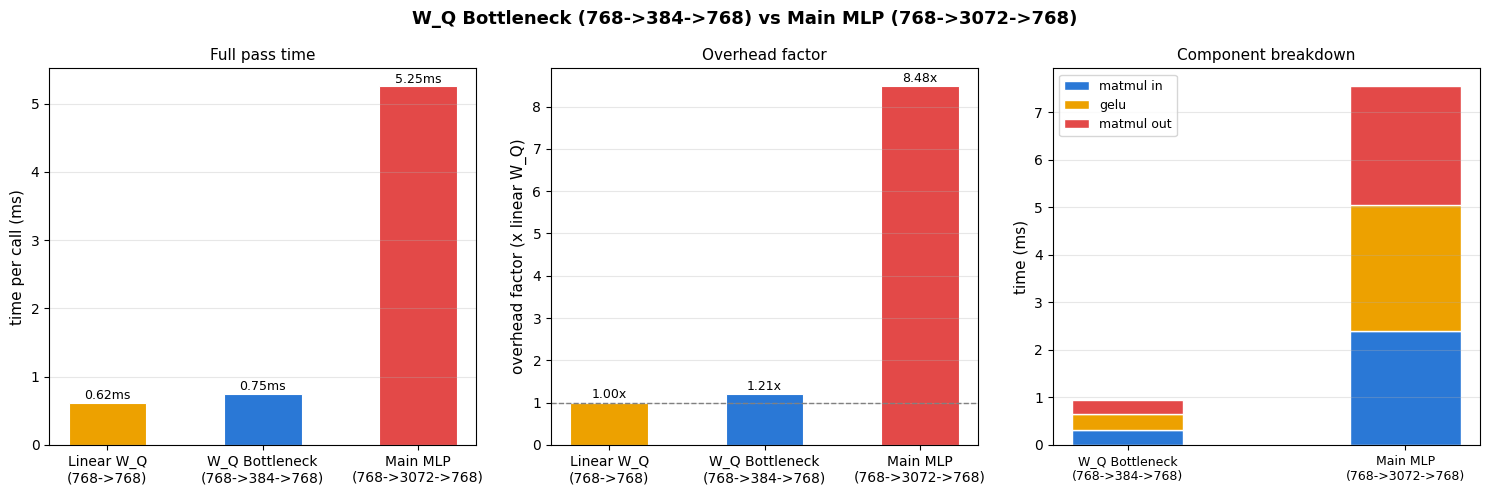

In [4]:
import torch
import time
import matplotlib.pyplot as plt
import numpy as np

B, T, C = 4, 512, 768
RUNS = 500
device = "cuda"

print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"B={B}, T={T}, C={C}, runs={RUNS}\n")

def bench(fn, runs=RUNS, warmup=50):
    for _ in range(warmup):
        fn()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs):
        fn()
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / runs * 1000

x    = torch.randn(B * T, C, device=device)
W_q  = torch.randn(C, C, device=device)
gelu = torch.nn.GELU()

t_linear = bench(lambda: x @ W_q)

# ── W_Q bottleneck: 768->384->768 ────────────────────────────────────────────
h1     = 384
W_in1  = torch.randn(C,  h1, device=device)
W_out1 = torch.randn(h1, C,  device=device)

def full_384():
    h = x @ W_in1
    return gelu(h) @ W_out1 + x

t_in1   = bench(lambda: x @ W_in1)
h_384   = gelu(x @ W_in1)
t_gel1  = bench(lambda: gelu(x @ W_in1))
t_out1  = bench(lambda: h_384 @ W_out1)
t_full1 = bench(full_384)

# ── main MLP: 768->3072->768 ──────────────────────────────────────────────────
h2     = 3072
W_in2  = torch.randn(C,  h2, device=device)
W_out2 = torch.randn(h2, C,  device=device)

def full_3072():
    h = x @ W_in2
    return gelu(h) @ W_out2 + x

t_in2   = bench(lambda: x @ W_in2)
h_3072  = gelu(x @ W_in2)
t_gel2  = bench(lambda: gelu(x @ W_in2))
t_out2  = bench(lambda: h_3072 @ W_out2)
t_full2 = bench(full_3072)

# ── print ─────────────────────────────────────────────────────────────────────
for label, t_in, t_gel, t_out, t_full in [
    ("W_Q bottleneck 768->384->768", t_in1, t_gel1, t_out1, t_full1),
    ("Main MLP       768->3072->768", t_in2, t_gel2, t_out2, t_full2),
]:
    total = t_in + t_gel + t_out
    print(f"\n{label}")
    print(f"  matmul in  : {t_in:.4f} ms  ({t_in/total*100:.1f}%)")
    print(f"  gelu       : {t_gel:.4f} ms  ({t_gel/total*100:.1f}%)")
    print(f"  matmul out : {t_out:.4f} ms  ({t_out/total*100:.1f}%)")
    print(f"  full pass  : {t_full:.4f} ms  |  {t_full/t_linear:.2f}x vs linear W_Q")

# ── plots ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("W_Q Bottleneck (768->384->768) vs Main MLP (768->3072->768)", fontsize=13, fontweight="bold")

configs   = ["Linear W_Q\n(768->768)", "W_Q Bottleneck\n(768->384->768)", "Main MLP\n(768->3072->768)"]
t_fulls   = [t_linear, t_full1, t_full2]
colors    = ["#eda100", "#2a78d6", "#e34948"]

# ax1: full pass comparison
ax = axes[0]
bars = ax.bar(configs, t_fulls, color=colors, edgecolor="white", linewidth=0.8, width=0.5)
for bar, val in zip(bars, t_fulls):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f"{val:.2f}ms", ha="center", fontsize=9)
ax.set_ylabel("time per call (ms)", fontsize=11)
ax.set_title("Full pass time", fontsize=11)
ax.grid(True, alpha=0.3, axis="y")

# ax2: overhead factor
ax = axes[1]
factors = [1.0, t_full1/t_linear, t_full2/t_linear]
bars = ax.bar(configs, factors, color=colors, edgecolor="white", linewidth=0.8, width=0.5)
ax.axhline(1.0, color="gray", ls="--", lw=1)
for bar, val in zip(bars, factors):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
            f"{val:.2f}x", ha="center", fontsize=9)
ax.set_ylabel("overhead factor (x linear W_Q)", fontsize=11)
ax.set_title("Overhead factor", fontsize=11)
ax.grid(True, alpha=0.3, axis="y")

# ax3: component breakdown stacked bar
ax = axes[2]
labels   = ["W_Q Bottleneck\n(768->384->768)", "Main MLP\n(768->3072->768)"]
ins      = [t_in1,  t_in2]
gels     = [t_gel1, t_gel2]
outs     = [t_out1, t_out2]
x_pos    = np.arange(len(labels))
width    = 0.4

ax.bar(x_pos, ins,  width, label="matmul in",  color="#2a78d6", edgecolor="white")
ax.bar(x_pos, gels, width, bottom=ins, label="gelu", color="#eda100", edgecolor="white")
ax.bar(x_pos, outs, width, bottom=[i+g for i,g in zip(ins,gels)], label="matmul out", color="#e34948", edgecolor="white")

ax.set_xticks(x_pos)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("time (ms)", fontsize=11)
ax.set_title("Component breakdown", fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("benchmark_correct_dims.png", dpi=150, bbox_inches="tight")
print("\nSaved: benchmark_correct_dims.png")

GPU: NVIDIA GeForce RTX 3050 Laptop GPU
  mlp_mult    hidden      bottleneck        linear    overhead
-----------------------------------------------------------------
     0.500       384          0.7672        0.6298        1.22x
     1.000       768          1.4020        0.5902        2.38x
     2.000      1536          2.4840        0.5809        4.28x
     3.000      2304          3.6292        0.5957        6.09x
     4.000      3072          5.2671        0.6790        7.76x
     4.330      3325          5.9992        0.6247        9.60x
     4.500      3456          5.6690        0.6043        9.38x
     4.625      3552          5.8089        0.5921        9.81x
     4.750      3648          6.1678        0.6124       10.07x

Saved: overhead_vs_nufrac_corrected.png

=== Key takeaways (corrected) ===
  actual W_Q bottleneck overhead : 1.22x  (0.7672 ms vs linear W_Q)
  nu_frac range (residual_gelu)  : 0.0266 -- 0.1834  (6.9x spread)
  -> W_Q nonlinearity costs almost nothing (

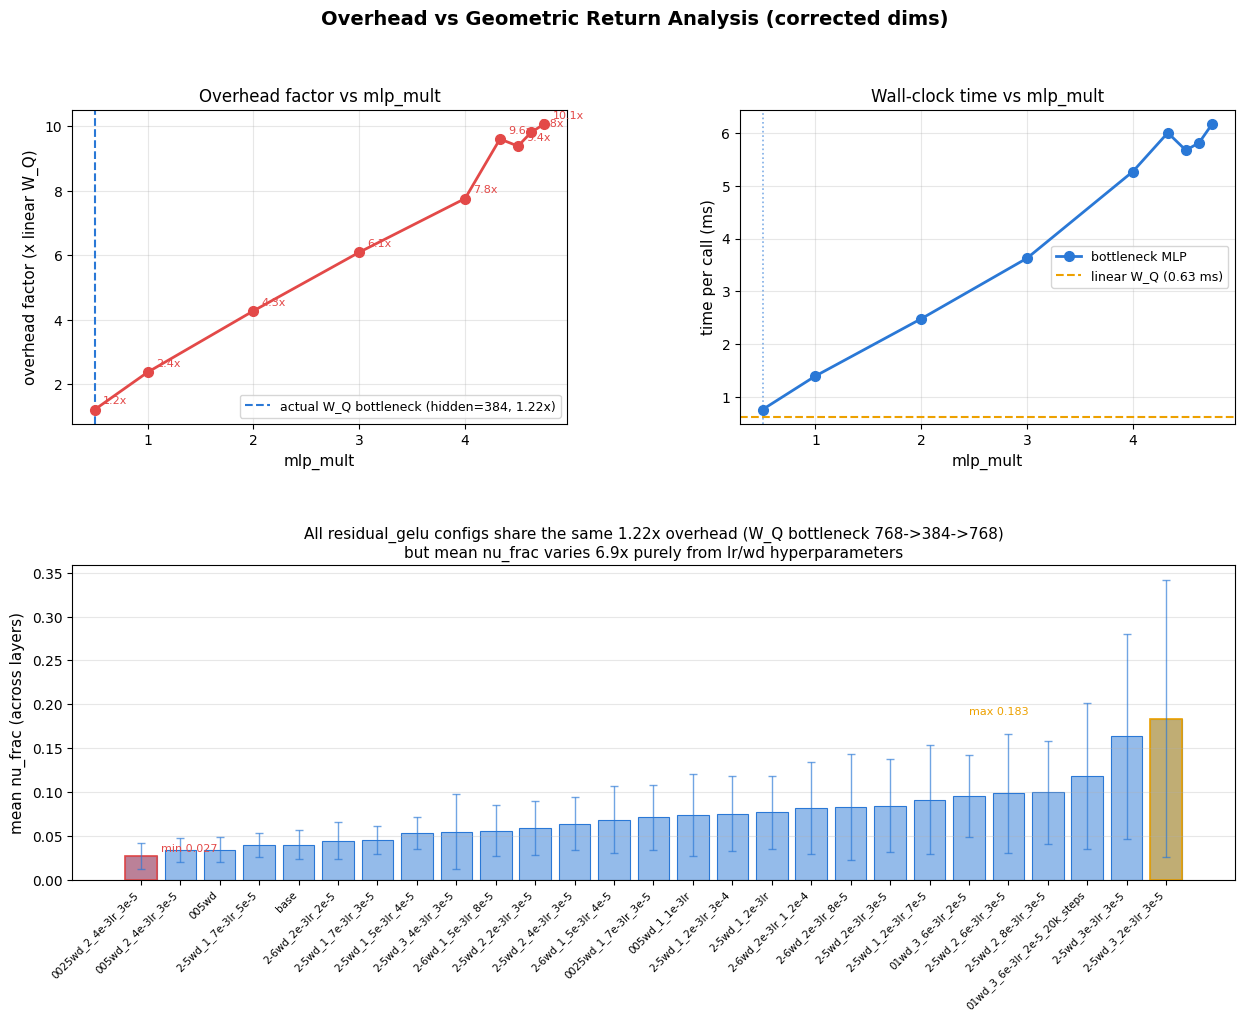

In [5]:
import torch
import time
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import os

B, T, C = 4, 512, 768
RUNS     = 500
DEVICE   = "cuda"
CSV_PATH = r"D:\modification research\checkpoint\sweep_results.csv"  # change if needed

MULT_VALUES = [0.5, 1.0, 2.0, 3.0, 4.0, 4.33, 4.5, 4.625, 4.75]

def bench(fn, runs=RUNS, warmup=50):
    for _ in range(warmup):
        fn()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs):
        fn()
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / runs * 1000

def benchmark_overhead(mlp_mult):
    mlp_hidden = int(mlp_mult * C)
    x     = torch.randn(B * T, C,          device=DEVICE)
    W_in  = torch.randn(C,          mlp_hidden, device=DEVICE)
    W_out = torch.randn(mlp_hidden, C,          device=DEVICE)
    W_q   = torch.randn(C,          C,          device=DEVICE)
    gelu  = torch.nn.GELU()
    def full():
        h = x @ W_in
        return gelu(h) @ W_out + x
    t_full   = bench(full)
    t_linear = bench(lambda: x @ W_q)
    return t_full, t_linear, t_full / t_linear

print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"{'mlp_mult':>10}  {'hidden':>8}  {'bottleneck':>14}  {'linear':>12}  {'overhead':>10}")
print("-" * 65)

results = []
for m in MULT_VALUES:
    t_full, t_lin, factor = benchmark_overhead(m)
    results.append({"mlp_mult": m, "hidden": int(m*C),
                    "bottleneck_ms": t_full, "linear_ms": t_lin, "overhead_factor": factor})
    print(f"{m:>10.3f}  {int(m*C):>8}  {t_full:>14.4f}  {t_lin:>12.4f}  {factor:>10.2f}x")

df_bench = pd.DataFrame(results)

# actual W_Q bottleneck overhead (mlp_mult=0.5, hidden=384)
actual_overhead = df_bench[df_bench["mlp_mult"] == 0.5]["overhead_factor"].values[0]
actual_ms       = df_bench[df_bench["mlp_mult"] == 0.5]["bottleneck_ms"].values[0]

assert os.path.exists(CSV_PATH), f"CSV not found: {CSV_PATH}"
df = pd.read_csv(CSV_PATH)

rg = (df[df["config"].str.contains("residual_gelu")]
      .groupby("config")
      .agg(mean_nu_frac=("nu_frac", "mean"), std_nu_frac=("nu_frac", "std"))
      .reset_index()
      .sort_values("mean_nu_frac"))

def shorten(name):
    name = name.replace("tiedw_residual_gelu_", "")
    name = name.replace("tiedw_residual_gelu", "base")
    return name

fig = plt.figure(figsize=(15, 10))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

fig.suptitle("Overhead vs Geometric Return Analysis (corrected dims)", fontsize=14, fontweight="bold", y=0.98)

# ax1: overhead factor vs mlp_mult -- dashed line at 0.5 (actual W_Q bottleneck)
ax1.plot(df_bench["mlp_mult"], df_bench["overhead_factor"],
         "o-", color="#e34948", lw=2, ms=7, zorder=3)
ax1.axvline(0.5, color="#2a78d6", ls="--", lw=1.5,
            label=f"actual W_Q bottleneck (hidden=384, {actual_overhead:.2f}x)")
ax1.set_xlabel("mlp_mult", fontsize=11)
ax1.set_ylabel("overhead factor (x linear W_Q)", fontsize=11)
ax1.set_title("Overhead factor vs mlp_mult", fontsize=12)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)
for _, row in df_bench.iterrows():
    ax1.annotate(f"{row['overhead_factor']:.1f}x",
                 (row["mlp_mult"], row["overhead_factor"]),
                 textcoords="offset points", xytext=(6, 4), fontsize=8, color="#e34948")

# ax2: wall-clock time
ax2.plot(df_bench["mlp_mult"], df_bench["bottleneck_ms"],
         "o-", color="#2a78d6", lw=2, ms=7, label="bottleneck MLP")
ax2.axhline(df_bench["linear_ms"].iloc[0], color="#eda100", ls="--", lw=1.5,
            label=f"linear W_Q ({df_bench['linear_ms'].iloc[0]:.2f} ms)")
ax2.axvline(0.5, color="#2a78d6", ls=":", lw=1.2, alpha=0.6)
ax2.set_xlabel("mlp_mult", fontsize=11)
ax2.set_ylabel("time per call (ms)", fontsize=11)
ax2.set_title("Wall-clock time vs mlp_mult", fontsize=12)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

# ax3: nu_frac across residual_gelu configs -- updated title with correct overhead
labels = [shorten(c) for c in rg["config"]]
x_pos  = np.arange(len(labels))

ax3.bar(x_pos, rg["mean_nu_frac"],
        yerr=rg["std_nu_frac"], capsize=3,
        color="#2a78d680", edgecolor="#2a78d6", linewidth=0.8,
        error_kw={"elinewidth": 1, "ecolor": "#2a78d6aa"})
ax3.bar(x_pos[0],  rg["mean_nu_frac"].iloc[0],  color="#e3494880", edgecolor="#e34948", lw=1.2)
ax3.bar(x_pos[-1], rg["mean_nu_frac"].iloc[-1], color="#eda10080", edgecolor="#eda100", lw=1.2)

ax3.set_xticks(x_pos)
ax3.set_xticklabels(labels, rotation=45, ha="right", fontsize=7.5)
ax3.set_ylabel("mean nu_frac (across layers)", fontsize=11)
ax3.set_title(
    f"All residual_gelu configs share the same {actual_overhead:.2f}x overhead (W_Q bottleneck 768->384->768)\n"
    f"but mean nu_frac varies {rg['mean_nu_frac'].max()/rg['mean_nu_frac'].min():.1f}x purely from lr/wd hyperparameters",
    fontsize=11
)
ax3.grid(True, alpha=0.3, axis="y")
ax3.annotate(f"min {rg['mean_nu_frac'].iloc[0]:.3f}",
             (x_pos[0], rg['mean_nu_frac'].iloc[0]),
             xytext=(x_pos[0]+0.5, rg['mean_nu_frac'].iloc[0]+0.005), fontsize=8, color="#e34948")
ax3.annotate(f"max {rg['mean_nu_frac'].iloc[-1]:.3f}",
             (x_pos[-1], rg['mean_nu_frac'].iloc[-1]),
             xytext=(x_pos[-1]-5, rg['mean_nu_frac'].iloc[-1]+0.005), fontsize=8, color="#eda100")

plt.savefig("overhead_vs_nufrac_corrected.png", dpi=150, bbox_inches="tight")
print(f"\nSaved: overhead_vs_nufrac_corrected.png")
print(f"\n=== Key takeaways (corrected) ===")
print(f"  actual W_Q bottleneck overhead : {actual_overhead:.2f}x  ({actual_ms:.4f} ms vs linear W_Q)")
print(f"  nu_frac range (residual_gelu)  : {rg['mean_nu_frac'].min():.4f} -- {rg['mean_nu_frac'].max():.4f}  ({rg['mean_nu_frac'].max()/rg['mean_nu_frac'].min():.1f}x spread)")
print(f"  -> W_Q nonlinearity costs almost nothing (1.21x)")
print(f"  -> geometric return still varies 7x from lr/wd alone")